# Aprendizaje de Simbolo: `ParabolicMLPSymbol` con datos GRF (calor 1D)

Se aprende un simbolo escalar real $a_\theta:\mathbb{Z}^n\to\mathbb{R}$ con la reparametrizacion parabolica
$a_\theta(\mathbf{k})=\langle\mathbf{k}\rangle^m\big(c+(C-c)\,\sigma(g_\theta(\mathbf{k}/\langle\mathbf{k}\rangle))\big)$ para
$\mathbf{k}\neq0$ y $a_\theta(0)=0$, con $g_\theta$ una MLP con `Tanh`. Los datos son los de la ecuacion del
calor 1D del paper base (Sec. 5.1), con condiciones iniciales de un campo aleatorio gaussiano.

**Función de perdida**

$$\mathcal{L} = \lambda_{\text{traj}}\,\mathcal{L}_{\text{traj}} + \lambda_{\text{par}}\,\mathcal{L}_{\text{par}} + \lambda_{\text{class}}\,\mathcal{L}_{\text{class}}$$

- **Trayectoria:** $\mathcal{L}_{\text{traj}} = \mathbb{E}\big[|e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k}) - \hat u_{\text{ref}}(\mathbf{k},t)|^2\big]$
- **Parabolicidad (Def. 2.3):** $\mathcal{L}_{\text{par}} = \mathbb{E}\big[\max\big(0,\ |(a_\theta(\mathbf{k})+\lambda)^{-1}| - \kappa(1+|(\mathbf{k},\lambda)|^2)^{-m/2}\big)^2\big]$,
  sobre $\mathrm{Re}(\lambda)\ge 0$, $|(\mathbf{k},\lambda)|\ge\omega$.
- **Clase de simbolo $S^{m,\rho}$:**
  $\mathcal{L}_{\text{class}} = \mathbb{E}_{\mathbf{k}}\Big[\frac{1}{|A_\rho|}\sum_{\alpha\in A_\rho}\max\big(0,\ \langle\mathbf{k}\rangle^{|\alpha|-m}\,|\Delta^\alpha_k a_\theta(\mathbf{k})| - C_\alpha\big)^2\Big]$,
  con $A_\rho=\{\alpha\in\mathbb{N}_0^n : |\alpha|\le\rho\}$, $\langle\mathbf{k}\rangle=(1+|\mathbf{k}|^2)^{1/2}$ y
  $\Delta_{k_j}a(\mathbf{k})=a(\mathbf{k}+e_j)-a(\mathbf{k})$. 
Como referencia se usa el simbolo del calor $a(k) = |k|^2$ en $\mathbb{T}^1$
($n=1$, $m=2$, $\rho=n+1=2$ para el simbolo aprendido).

# Setup
- **Datos:** los GRF de `01_exploracion.ipynb`, seccion 2.1, en `float64`. La particion entrenamiento /
  validacion es **por $\mathbf{k}$** (80% / 20% de los $k$ unicos): todas las muestras de un mismo $k$ caen en
  el mismo conjunto, asi que los $k$ de validacion nunca se ven en entrenamiento. Aparte hay un conjunto de
  **prueba**: condiciones iniciales nuevas y una rejilla temporal mas fina.
- **$\kappa$:** $\kappa=$ `theoretical_kappa()`, con $c$ y $C$ estimados de los datos de entrenamiento
  (`estimate_symbol` + `estimate_bounds`, $\delta=0.1$):
  $\kappa=\max\big(\sqrt2\,M/\min(c,1),\ M(1+\omega^{-m})\big)$ con $M=\max(1,2^{m/2-1})$. Con ese $\kappa$
  la Def. 2.3 se cumple en todo $\mathbb Z^n$ para cualquier $\theta$, por la banda $c<a_\theta/\langle\mathbf k\rangle^m<C$. Las $C_\alpha$ de $\mathcal{L}_{\text{class}}$
  salen del mismo $\hat a(\mathbf{k})$ (`estimate_class_constants`), con margen $1.5$.
- **Arquitecturas probadas:** barrido de $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas.
- **Regularizacion:** dropout $0.2$ en las capas ocultas interiores (se compara `none` frente a
  `middle`), weight decay $\{0,\ 10^{-4}\}$ en las `Linear` ocultas interiores, y **early stopping**
  sobre la perdida total de validacion, **incluyendo $\mathcal{L}_{\text{class}}$** (evaluada cada epoca
  sobre un conjunto fijo de $\mathbf{k}$ con $|k_i|\le k_{\max}$).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from parabolic_symbol.verification.parabolicity import ParabolicityVerifier
from parabolic_symbol.verification.symbol_class import SymbolClassVerifier
from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.utils import default_device
from parabolic_symbol.symbols.parabolic_mlp_symbol import ParabolicMLPSymbol
from parabolic_symbol.data.grids import k_grid, phase_grid, split_trajectory_data
from parabolic_symbol.data.grf import field_rel_l2, heat_grf_datasets
from parabolic_symbol.learning.estimation import (
    estimate_bounds,
    estimate_class_constants,
    estimate_symbol,
    oracle_class_constants,
)
from parabolic_symbol.learning.experiment import class_C_table
from parabolic_symbol.learning.evaluation import max_ratio_on, symbol_report, trajectory_report
from parabolic_symbol.learning.sweep import best_run, run_sweep, sweep_table
from parabolic_symbol.learning.training import TrainingConfig

np.set_printoptions(precision=4, suppress=True)

device = default_device()
dtype = torch.float64
print(f"device = {device}  |  dtype = {dtype}")

RESULTS = Path("../results/02_calor_1d")   # tabla del barrido (CSV) y figuras (PNG)
RESULTS.mkdir(parents=True, exist_ok=True)

device = cuda  |  dtype = torch.float64


## 1. Datos de referencia

Calor $a(k)=|k|^2$ (`HeatSymbol`) en $\mathbb{T}^1=[0,2\pi)$, malla de $1024$ puntos. Generacion de los datos
GRF y tiempos: ver `01_exploracion.ipynb`, seccion 2.1. Se usan todos los pares $(k,t)$ con
$|k|\le k_{\text{cap}}=64$, y $k_{\max}=k_{\text{cap}}$ en el resto del notebook.


In [2]:
n = 1
reference = HeatSymbol(n=n)
k_cap = 64

grf_train, grf_test = heat_grf_datasets(reference, resolution=1024, seed=0, k_cap=k_cap)
test_data = grf_test.split
k_max = k_cap   # puntos de parabolicidad y ventana de certificacion

# Particion por k: cada k unico va entero a entrenamiento o a validacion.
train_data, val_data = split_trajectory_data(grf_train.split, val_fraction=0.2, seed=0)

k_train_values = np.unique(train_data["k"].numpy(), axis=0)
k_val_values = np.unique(val_data["k"].numpy(), axis=0)

print()
print(f"k_max = k_cap = {k_max}")
print(f"entrenamiento: {train_data['k'].shape[0]:,} muestras / {len(k_train_values)} k unicos")
print(f"validacion:    {val_data['k'].shape[0]:,} muestras / {len(k_val_values)} k unicos")
print(f"prueba:        {test_data['k'].shape[0]:,} muestras / {grf_test.window.n_k} k unicos")


ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]

k_max = k_cap = 64
entrenamiento: 103,000 muestras / 103 k unicos
validacion:    26,000 muestras / 26 k unicos
prueba:        51,600 muestras / 129 k unicos


## 2. $\kappa$ teorico y constantes $C_\alpha$

$c$ y $C$ se estiman solo con los datos de entrenamiento y fijan $\kappa=$ `theoretical_kappa()`.
$\hat\kappa$ del simbolo de referencia se calcula solo como comparacion.
**Filtro de senal** de `estimate_symbol`: se descartan los pares con $|\hat u|\le 10^{-10}|\hat u_0|$, porque
$\log|\hat u/\hat u_0|$ no tiene sentido cuando $\hat u$ es cero o ruido de redondeo; solo afecta a esta estimacion.
Las constantes $C_\alpha$ de $\mathcal{L}_{\text{class}}$ salen del mismo $\hat a(\mathbf{k})$ de entrenamiento,
por diferencias finitas sobre los $k$ cuyo estencil completo esta en el conjunto, con un margen $1.5$.
La tabla muestra las $C_\alpha$ de los datos (las que se usan), las del simbolo exacto (oraculo, solo como
comparacion, no entran al entrenamiento) y cuantos $k$ de entrenamiento se usaron para cada $\alpha$.

In [3]:
omega = 1.0
k_values = list(k_grid(n, k_max))
lam_values = [complex(re, im) for re in (0, 1, 5, 10, 25, 50) for im in (-50, -10, -2, 0, 2, 10, 50)]

kappa_ref = ParabolicityVerifier(reference).estimate_kappa(k_values, lam_values, omega=omega)

# Simbolo a_hat(k) estimado de los datos de ENTRENAMIENTO: de el salen (c, C) y las C_alpha
k_est, a_hat = estimate_symbol(train_data, tol=1e-10)
bounds = estimate_bounds(k_est, a_hat, m=2.0, delta=0.1)
probe = ParabolicMLPSymbol(n=n, m=2.0, c=bounds.c, C=bounds.C, seed=0, device=device, dtype=dtype)
kappa_theo = probe.theoretical_kappa(omega)

# Constantes C_alpha de la Def. 2.1 para L_class, por diferencias finitas de a_hat sobre los k
# de entrenamiento, para todos los alpha con |alpha| <= rho del simbolo aprendido.
class_margin = 1.5
class_C, class_C_counts = estimate_class_constants(
    k_est, a_hat, 2.0, rho=probe.rho, margin=class_margin, return_counts=True
)
# Las del simbolo exacto en |k_i| <= k_max: solo para comparar, no se entrenan con ellas.
class_C_oracle = oracle_class_constants(reference, k_max, margin=class_margin, rho=probe.rho)

print(f"kappa_hat referencia = {kappa_ref:.4f}")
print(f"(c, C) de los datos  = ({bounds.c:.4f}, {bounds.C:.4f})   ventana: {bounds.window}")
print(f"kappa teorico        = {kappa_theo:.4f}")

tabla_C = class_C_table(class_C, class_C_oracle, class_C_counts, class_margin)
tabla_C.to_csv(RESULTS / "class_C.csv")
display(tabla_C)

estimate_symbol: 13,100 de 103,000 pares (k, t) con senal (tol=1e-10); 35 de 103 k de entrenamiento
  ventana usada: 35 k, |k|_inf <= 21, |k| in [0, 21]
kappa_hat referencia = 2.0000
(c, C) de los datos  = (0.4500, 1.0975)   ventana: 34 k, |k|_inf <= 21, |k| in [1, 21]
kappa teorico        = 3.1427


,C_alpha datos (x1.5),C_alpha oraculo (x1.5),k_usados
alpha,,,
"(0,)",1.496606,1.499634,35
"(1,)",3.354102,3.354102,29
"(2,)",3.000000,3.000000,24


## 3. Barrido de hiperparametros

Ejes: $3$ profundidades $\times$ $3$ anchos $\times$ ubicacion del dropout $\times$ $2$ weight decays $=$
**30 entrenamientos**, todos con $\kappa=$ `theoretical_kappa()`.

- **Dropout:** tasa **fija** de $0.2$; lo que se compara es *donde* se aplica, `none` frente a `middle`
  (capas ocultas interiores, excluyendo la primera y la ultima). Con $2$ capas ocultas `middle` no deja
  ninguna capa, asi que equivale a `none` y esa corrida no se repite.
- **Weight decay:** $\{0,\ 10^{-4}\}$, solo sobre las `Linear` ocultas interiores.


In [4]:
# Configuracion base: valores por defecto de TrainingConfig (learning/training.py); solo
# k_max y las C_alpha dependen de los datos.
base_config = TrainingConfig(k_max=k_max, class_C=class_C)

runs = run_sweep(
    train_data,
    val_data,
    n=n,
    m=2.0,
    bounds=(bounds.c, bounds.C),
    depths=[2, 3, 4],
    widths=[32, 64, 128],
    base_config=base_config,
    dropout=0.2,
    dropout_layers=["none", "middle"],
    weight_decays=[0.0, 1e-4],
    device=device,
    dtype=dtype,
)


[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.2506 |  18.1s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.2506 |  15.6s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0034 |  38.2s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0034 |  40.7s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0052 |  51.2s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0052 |  51.0s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0169 |  26.6s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0169 |  27.2s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.1170 |  18.7s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.1170 |  17.6s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0113 |  31.2s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0113 |  30.9s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.1051 |  19.5s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.1051 |  19.8s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0083 |  71.3s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0083 |  71.3s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.1219 |  47.5s
[ 18/30] 3x128 drop[1] wd=1e-04

## 4. Resultados del barrido

In [5]:
table = sweep_table(runs)
table.to_csv(RESULTS / "barrido.csv", index=False)
print(f"{len(table)} corridas, {table['segundos'].sum() / 60:.1f} min de entrenamiento en total")

# Todas las corridas, de mejor a peor error relativo de validacion:
COLS = ["capas", "ancho", "dropout", "weight_decay",
        "val_rel_l2", "val_total", "val_par_max_ratio"]
display(table[COLS].sort_values("val_rel_l2").reset_index(drop=True))


30 corridas, 20.5 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,2,64,OFF,0.0000,0.003368,1.395708e-09,0.709565
1,2,64,OFF,0.0001,0.003368,1.395831e-09,0.709562
2,2,128,OFF,0.0000,0.005178,3.298528e-09,0.709095
3,2,128,OFF,0.0001,0.005179,3.299217e-09,0.709094
4,3,128,OFF,0.0000,0.008296,8.467412e-09,0.708224
5,3,128,OFF,0.0001,0.008297,8.467763e-09,0.708224
6,3,64,OFF,0.0001,0.011324,1.577577e-08,0.709970
7,3,64,OFF,0.0000,0.011327,1.578443e-08,0.709970
8,3,32,OFF,0.0001,0.016925,3.524082e-08,0.708446
9,3,32,OFF,0.0000,0.016929,3.525635e-08,0.708447


In [6]:
# Por configuracion de regularizacion (dropout / weight decay).
for eje in ("dropout", "weight_decay"):
    if table[eje].nunique() > 1:
        display(
            table.groupby(eje).agg(
                corridas=("val_rel_l2", "size"),
                mejor_val_rel_l2=("val_rel_l2", "min"),
                mejor_val_total=("val_total", "min"),
                peor_ratio=("val_par_max_ratio", "min"),
            )
        )


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.003368,1.395708e-09,0.571455
"ON p=0.2 capas[1,2]",6,0.104214,1.342482e-06,0.530135
ON p=0.2 capas[1],6,0.105139,1.359890e-06,0.530599


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.003368,1.395708e-09,0.530135
0.0001,15,0.003368,1.395831e-09,0.530135


### Seleccion: la mejor aproximacion

Todas las corridas usan el mismo $\kappa=$ `theoretical_kappa()`, con el que la Def. 2.3 se satisface por
construccion, asi que se elige la de **menor error relativo de validacion** de la trayectoria.

El modelo elegido se guarda en `modelo.pt` (celda siguiente) y la seccion 9 lo usa.

In [7]:
best = best_run(runs)

symbol = best.symbol
print(f"kappa = theoretical_kappa() = {best.kappa:.4f}")

# Kappa que realmente exhibe el simbolo aprendido, medido sobre la REJILLA DE
# CERTIFICACION (seccion 7). Junto a kappa_ref (celda 6) dice
# cuanto se alejo el simbolo aprendido del simbolo verdadero.
cert_radii = np.logspace(-2, 3, 25)                    # |lambda| en [1e-2, 1e3]
cert_angles = np.linspace(-np.pi / 2, np.pi / 2, 25)   # incluye la frontera Re(lambda) = 0
cert_lam = (cert_radii[:, None] * np.exp(1j * cert_angles)).ravel()
cert_k_max = 3 * k_max

kappa_learned = ParabolicityVerifier(symbol).estimate_kappa(
    list(k_grid(n, cert_k_max)), cert_lam, omega=omega
)
print(f"kappa_hat aprendido         = {kappa_learned:.4f}   (certificacion, |k_i| <= {cert_k_max})")
print(f"kappa_hat referencia        = {kappa_ref:.4f}   (simbolo analitico, celda 6)")

print(f"arquitectura elegida    = {best.n_layers} capas x {best.width} neuronas")
print(f"dropout                 = {best.dropout_desc}")
print(f"weight decay            = {best.weight_decay:g}  (Linear ocultas interiores)")
print(f"early stopping          = mejor epoca {best.best_epoch} de {best.epochs_run} corridas")
print()
print("metricas de validacion en la mejor epoca:")
print(f"  total             = {best.val_total:.4e}")
print(f"  trayectoria       = {best.val_trajectory:.4e}")
print(f"  parabolicidad     = {best.val_parabolicity:.4e}   (0 => ningun punto viola la cota)")
print(f"  rel_l2            = {best.val_rel_l2:.4f}")
print(f"  peor ratio        = {best.val_par_max_ratio:.4f}")
print(f"  puntos con >1     = {100 * best.val_par_violation:.2f}%")


kappa = theoretical_kappa() = 3.1427
kappa_hat aprendido         = 2.2373   (certificacion, |k_i| <= 192)
kappa_hat referencia        = 2.0000   (simbolo analitico, celda 6)
arquitectura elegida    = 2 capas x 64 neuronas
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 42 de 72 corridas

metricas de validacion en la mejor epoca:
  total             = 1.3957e-09
  trayectoria       = 1.3957e-09
  parabolicidad     = 0.0000e+00   (0 => ningun punto viola la cota)
  rel_l2            = 0.0034
  peor ratio        = 0.7096
  puntos con >1     = 0.00%


In [8]:
# Modelo elegido -> results/02_calor_1d/modelo.pt: pesos y todo lo necesario para reconstruirlo
# y regenerar sus datos sin este notebook (seccion 9).
from parabolic_symbol.learning.experiment import save_experiment_model

save_experiment_model(RESULTS / "modelo.pt", best, reference=reference, m=2.0, resolution=1024, k_cap=k_cap,
                      config=base_config, seed=0, val_fraction=0.2, dtype=dtype, omega=omega)

modelo guardado en ../results/02_calor_1d/modelo.pt


PosixPath('../results/02_calor_1d/modelo.pt')

### Metricas del modelo seleccionado

Se presentan dos reportes distintos:

- **Trayectoria** $\hat u(\mathbf{k},t) = e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k})$, sobre las muestras
  de entrenamiento y de validacion.
- **Simbolo** $a_\theta(\mathbf{k})$ frente a $|\mathbf{k}|^2$, por separado sobre los $k$ de entrenamiento y
  los $k$ de validacion (estos ultimos la red nunca los vio).

Se reportan RMSE, MAE y $R^2$.

In [9]:
traj = {"entrenamiento": trajectory_report(symbol, train_data),
        "validacion": trajectory_report(symbol, val_data)}
n_muestras = {split: int(rep.pop("n")) for split, rep in traj.items()}

print("TRAYECTORIA  -- residuo complejo |u_pred - u_ref|")
print(f"  muestras: {n_muestras['entrenamiento']:,} entrenamiento / {n_muestras['validacion']:,} validacion")
display(pd.DataFrame(traj))

# El split es por k, asi que el simbolo se reporta por separado sobre los k de
# entrenamiento y sobre los k de validacion, que la red nunca vio.
sym = {"entrenamiento": symbol_report(symbol, reference, k_train_values),
       "validacion": symbol_report(symbol, reference, k_val_values)}
n_k = {split: int(rep.pop("n")) for split, rep in sym.items()}

print("SIMBOLO  -- a_theta(k) vs |k|^2")
print(f"  k unicos: {n_k['entrenamiento']} de entrenamiento / {n_k['validacion']} de validacion")
display(pd.DataFrame(sym))

print("PARABOLICIDAD")
print(f"  kappa usada             = {best.kappa:.4f}")
print(f"  hinge^2 de validacion   = {best.val_parabolicity:.4e}")


TRAYECTORIA  -- residuo complejo |u_pred - u_ref|
  muestras: 103,000 entrenamiento / 26,000 validacion


,entrenamiento,validacion
mse,1.577895e-09,1.395708e-09
rmse,3.972273e-05,3.735917e-05
mae,5.421214e-06,6.680301e-06
max_error,1.289833e-03,7.908609e-04
rel_l2,1.935524e-03,3.368295e-03
r2,9.999963e-01,9.999887e-01


SIMBOLO  -- a_theta(k) vs |k|^2
  k unicos: 103 de entrenamiento / 26 de validacion


,entrenamiento,validacion
mse,4142.783652,4040.874574
rmse,64.364460,63.567874
mae,47.843304,46.912471
max_error,143.159827,140.191340
rel_l2,0.034524,0.034464


PARABOLICIDAD
  kappa usada             = 3.1427
  hinge^2 de validacion   = 0.0000e+00


### Evaluacion en prueba

Condiciones iniciales nuevas y rejilla temporal fina ($20$ tiempos, incluidos tiempos que no estan en
entrenamiento). Se reportan dos errores relativos $L^2$:

- sobre los pares $(k,t)$ del conjunto de prueba (el mismo `trajectory_report`);
- en espacio fisico, como en el paper: $\|u_\theta(t,\cdot)-u(t,\cdot)\|_{L^2}/\|u(t,\cdot)\|_{L^2}$ en la malla
  de $1024$ puntos, con todos los modos, por condicion inicial y tiempo, promediado.


PRUEBA  -- 51,600 pares (k, t), 20 condiciones iniciales nuevas


,prueba
mse,9.530797e-10
rmse,3.087199e-05
mae,4.359076e-06
max_error,8.924098e-04
rel_l2,1.711750e-03
r2,9.999971e-01


error relativo L2 (pares (k, t))        = 1.7117e-03
error relativo L2 (espacio fisico)     = 8.4620e-04  (medio; max 6.8229e-03)


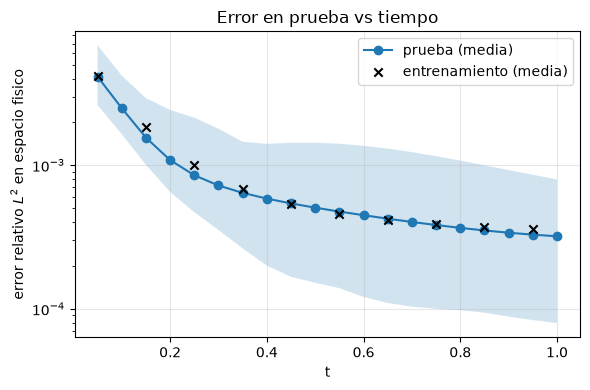

In [10]:
test_traj = trajectory_report(symbol, test_data)
test_traj.pop("n")
print(f"PRUEBA  -- {test_data['k'].shape[0]:,} pares (k, t), {grf_test.u0_hat.shape[0]} condiciones iniciales nuevas")
display(pd.DataFrame({"prueba": test_traj}))

err_field = field_rel_l2(symbol, grf_test)   # (n_ic, T)
print(f"error relativo L2 (pares (k, t))        = {test_traj['rel_l2']:.4e}")
print(f"error relativo L2 (espacio fisico)     = {err_field.mean():.4e}  "
      f"(medio; max {err_field.max():.4e})")

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(grf_test.t, err_field.mean(axis=0), "o-", label="prueba (media)")
ax.fill_between(grf_test.t, err_field.min(axis=0), err_field.max(axis=0), alpha=0.2)
ax.scatter(grf_train.t, field_rel_l2(symbol, grf_train).mean(axis=0), color="k", marker="x",
           zorder=3, label="entrenamiento (media)")
ax.set_xlabel("t")
ax.set_ylabel(r"error relativo $L^2$ en espacio fisico")
ax.set_title("Error en prueba vs tiempo")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS / "error_prueba.png", dpi=150)
plt.show()


## 5. Curvas de entrenamiento

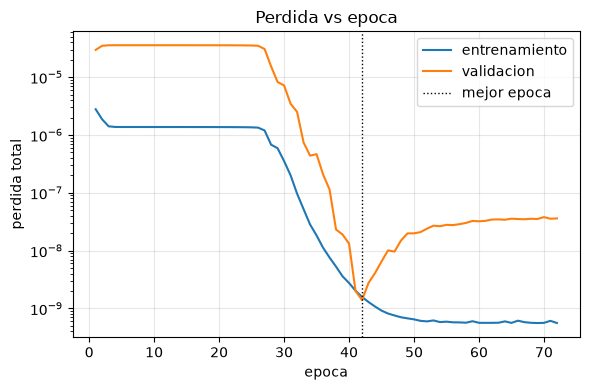

In [11]:
history = best.result.history
epochs = np.arange(1, len(history["train"]["total"]) + 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(epochs, history["train"]["total"], label="entrenamiento")
ax.semilogy(epochs, history["val"]["total"], label="validacion")
ax.axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
ax.set_xlabel("epoca")
ax.set_ylabel("perdida total")
ax.set_title("Perdida vs epoca")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(RESULTS / "perdida.png", dpi=150)
plt.show()


La perdida total graficada es la que registra `evaluate_split`: trayectoria + parabolicidad +
$\mathcal{L}_{\text{class}}$ (por `early_stopping_class=True`), y el early stopping usa esa misma cantidad.

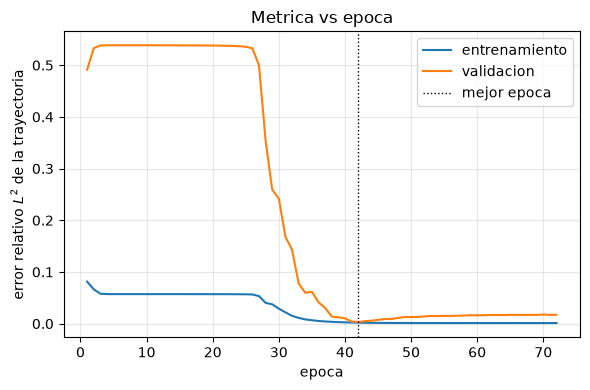

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(epochs, history["train"]["rel_l2"], label="entrenamiento")
ax.plot(epochs, history["val"]["rel_l2"], label="validacion")
ax.axvline(best.best_epoch, color="k", ls=":", lw=1, label="mejor epoca")
ax.set_xlabel("epoca")
ax.set_ylabel(r"error relativo $L^2$ de la trayectoria")
ax.set_title("Metrica vs epoca")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig(RESULTS / "rel_l2.png", dpi=150)
plt.show()


**Nota:** La linea punteada vertical marca la epoca cuyos pesos restauro el early stopping.

## 6. Simbolo aprendido vs. referencia

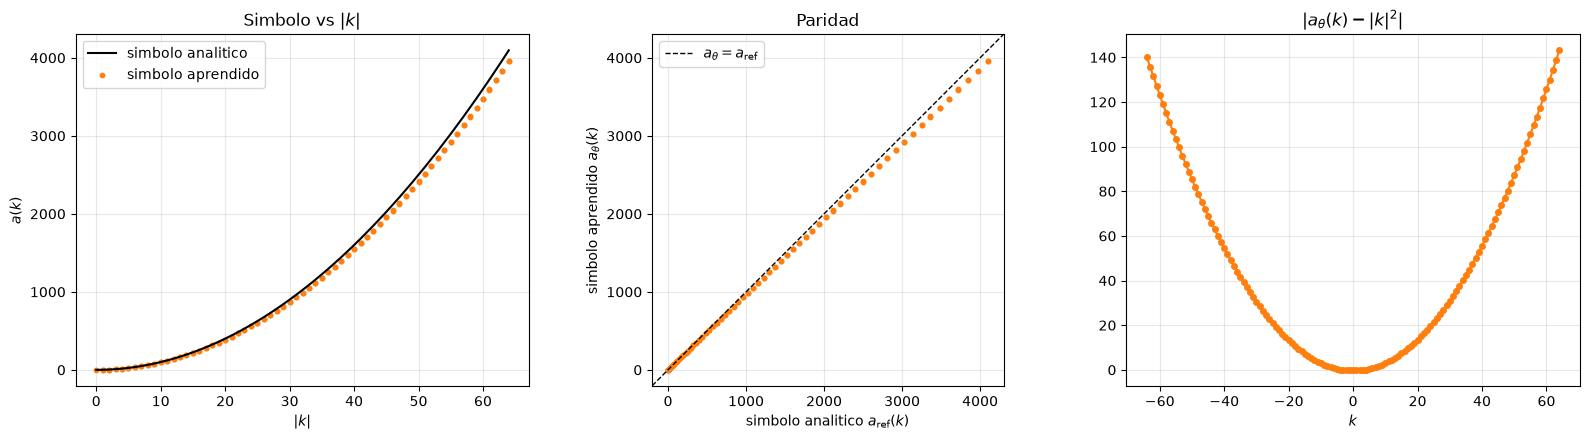

error relativo medio = 0.031, maximo = 0.035


In [13]:
k_arr = np.array(k_values)
a_true = np.array([reference(k)[0, 0] for k in k_values])
a_learn = symbol.evaluate_batch(k_arr)   # un solo forward por lotes
norm_k2 = np.sum(k_arr**2, axis=1)
norm_k = np.linalg.norm(k_arr, axis=1)

# Los dos simbolos son reales; np.real descarta la parte imaginaria nula que
# arrastra la interfaz compleja de Symbol.
a_ref_r, a_theta_r = np.real(a_true), np.real(a_learn)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# (a) La curva del simbolo. Para el calor, a(k) = |k|^2 es una parabola en |k|.
order = np.argsort(norm_k)
axes[0].plot(norm_k[order], a_ref_r[order], "k-", lw=1.5, label="simbolo analitico")
axes[0].scatter(norm_k, a_theta_r, s=10, color="C1", label="simbolo aprendido")
axes[0].set_xlabel(r"$|k|$")
axes[0].set_ylabel(r"$a(k)$")
axes[0].set_title(r"Simbolo vs $|k|$")
axes[0].legend()
axes[0].grid(alpha=0.3)

# (b) Paridad: cada k es un punto; sobre la diagonal significa que a_theta acerto.
lo = min(a_ref_r.min(), a_theta_r.min())
hi = max(a_ref_r.max(), a_theta_r.max())
pad = 0.05 * (hi - lo)
lims = [lo - pad, hi + pad]
axes[1].plot(lims, lims, "k--", lw=1, label=r"$a_\theta = a_{\text{ref}}$")
axes[1].scatter(a_ref_r, a_theta_r, s=10, color="C1")
axes[1].set_xlim(lims)
axes[1].set_ylim(lims)
axes[1].set_aspect("equal")
axes[1].set_xlabel(r"simbolo analitico $a_{\mathrm{ref}}(k)$")
axes[1].set_ylabel(r"simbolo aprendido $a_\theta(k)$")
axes[1].set_title("Paridad")
axes[1].legend()
axes[1].grid(alpha=0.3)

# (c) Error absoluto sobre la rejilla de k (n = 1: una sola coordenada).
axes[2].plot(k_arr[:, 0], np.abs(a_learn - a_true), "o-", color="C1", ms=4)
axes[2].set_title(r"$|a_\theta(k) - |k|^2|$")
axes[2].set_xlabel(r"$k$")
axes[2].grid(alpha=0.3)
plt.tight_layout()
fig.savefig(RESULTS / "simbolo.png", dpi=150)
plt.show()

rel = np.abs(a_learn - a_true) / np.maximum(norm_k2, 1)
print(f"error relativo medio = {rel.mean():.3f}, maximo = {rel.max():.3f}")


Para $|\mathbf{k}|$ grande $e^{-t|\mathbf{k}|^2}\approx 0$ en casi todo el rango de $t$, asi que la perdida de
trayectoria da poca informacion alli y el error es mayor.

## 7. Certificacion de Parabolicidad

Def. 2.3 y el cociente que se maximiza: ver `01_exploracion.ipynb`, seccion 3.
La certificacion usa una rejilla **independiente** de `lam_values` (con la que se estimo $\hat\kappa$
de la referencia) y de los puntos de entrenamiento, y solo se evalua sobre el modelo ya elegido. Se
define en la celda de seleccion, que ya la usa para medir $\hat\kappa$ del simbolo aprendido:

- $k$ en $|k_i|\le 3k_{\max}$, tres veces la ventana de entrenamiento;
- $|\lambda|$ log-espaciado en $[10^{-2},10^{3}]$ con $25$ angulos en $[-\pi/2,\pi/2]$,
  extremos incluidos (la frontera $\mathrm{Re}(\lambda)=0$).


In [14]:
# Rejilla de CERTIFICACION (cert_lam, cert_k_max): definida en la celda de seleccion.


def cert_max_ratio(k_window, chunk=200_000):
    """Peor ratio sobre (|k_i| <= k_window) x cert_lam, por trozos para no llenar memoria."""
    kk, ll = phase_grid(n, k_window, cert_lam, device=device, dtype=dtype)
    return max(
        max_ratio_on(symbol, (kk[i : i + chunk], ll[i : i + chunk]), omega, best.kappa)
        for i in range(0, kk.shape[0], chunk)
    )


n_k_cert = len(k_grid(n, cert_k_max))
max_ratio = cert_max_ratio(cert_k_max)

print(f"{symbol!r}")
print(f"rejilla de certificacion: {n_k_cert:,} k (|k_i| <= {cert_k_max}) x "
      f"{len(cert_lam)} lambda = {n_k_cert * len(cert_lam):,} puntos")
print(f"kappa usada = {best.kappa:.4f}")
print(f"max ratio   = {max_ratio:.4f}   (<= 1 => la cota se satisface)")
print(f"satisfecha  = {max_ratio <= 1.0}")
print(f"kappa minimo que certificaria esta rejilla = {best.kappa * max_ratio:.4f}")


ParabolicMLPSymbol(c=0.45, C=1.098, hidden=(64, 64), sin dropout)(n=1, m=2.0, rho=2, dim=1)
rejilla de certificacion: 385 k (|k_i| <= 192) x 625 lambda = 240,625 puntos
kappa usada = 3.1427
max ratio   = 0.7119   (<= 1 => la cota se satisface)
satisfecha  = True
kappa minimo que certificaria esta rejilla = 2.2373


In [15]:
# Hasta donde alcanza: peor ratio por ventana de k, con la misma rejilla de lambda.
# La parabolicidad solo puede esperarse dentro de la ventana muestreada.
for window in (k_max, 2 * k_max, cert_k_max):
    ratio = cert_max_ratio(window)
    donde = "dentro" if window <= k_max else "fuera "
    print(f"|k_i| <= {window:3d} ({donde} de la ventana de entrenamiento): "
          f"max ratio = {ratio:.4f} -> {'se satisface' if ratio <= 1.0 else 'NO se satisface'}")


|k_i| <=  64 (dentro de la ventana de entrenamiento): max ratio = 0.7119 -> se satisface
|k_i| <= 128 (fuera  de la ventana de entrenamiento): max ratio = 0.7119 -> se satisface
|k_i| <= 192 (fuera  de la ventana de entrenamiento): max ratio = 0.7119 -> se satisface


## 8. Clase del simbolo: $S^{m,\rho}$

Def. 2.1 y criterio de `SymbolClassVerifier` (ventanas crecientes $\{|k_i|\le K\}$, pendiente log-log): ver
`01_exploracion.ipynb`, seccion 5. Aqui se aplica al simbolo aprendido, con $\rho = $ `symbol.rho`. **Es evidencia
en una ventana finita, no una prueba:** la definicion cuantifica sobre todo $\mathbb{Z}^n$, y la red solo esta
restringida donde se la entreno.

La misma desigualdad es la que penaliza $\mathcal{L}_{\text{class}}$ durante el entrenamiento, pero solo
en los $\mathbf{k}$ muestreados ($|k_i|\le k_{\max}$). Esta seccion mira ventanas mas grandes para ver si la
penalizacion se sostiene fuera de esa region.

In [16]:
class_k_maxs = (4, 8, 12, 2 * k_max)   # ventanas crecientes para ver si C_alpha se estabiliza
resultados_clase = SymbolClassVerifier(symbol).check(k_maxs=class_k_maxs)

clase = pd.DataFrame([
    {
        "alpha": str(r.alpha),
        "|alpha|": r.order,
        **{f"C_hat({K})": r.c_hat[K] for K in class_k_maxs},
        f"crecim.({class_k_maxs[-2]}->{class_k_maxs[-1]})": r.growth,
        "pendiente": r.slope,
        "m-|alpha|": r.slope_theoretical,
        "estable": r.stable,
        "consistente": r.consistent,
    }
    for r in resultados_clase
])
display(clase)

ok = int(clase["consistente"].sum())
print(f"consistentes: {ok} de {len(clase)} multiindices (rho = {symbol.rho}, m = {symbol.m})")
print(f"ventana explorada: |k_i| <= {class_k_maxs[-1]} (evidencia, no prueba sobre todo Z^n)")
print("pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta")

,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,"(0,)",0,0.932965,0.958114,0.962354,0.965624,1.003397,2.000121e+00,2.0,True,True
1,"(1,)",1,2.247804,2.247804,2.247804,2.247804,1.000000,9.946429e-01,1.0,True,True
2,"(2,)",2,2.023567,2.023567,2.023567,2.023567,1.000000,3.024591e-07,0.0,True,True


consistentes: 3 de 3 multiindices (rho = 2, m = 2.0)
ventana explorada: |k_i| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


## 9. Resultados (desde `modelo.pt`)

Esta seccion **carga** el modelo guardado tras la seleccion, reconstruye el simbolo y regenera los datos con la
misma semilla; se puede ejecutar sola, despues del Setup, sin volver a entrenar. Las figuras se guardan en
`results/02_calor_1d/`.

Si hay resultados de una corrida anterior pero no `modelo.pt`, la primera celda reentrena **solo** la
configuracion elegida (la mejor fila de `barrido.csv`), sin repetir el barrido, comprueba que reproduce su error
de validacion y guarda `modelo.pt`.

In [17]:
from parabolic_symbol.learning import figures
from parabolic_symbol.learning.experiment import GRFExperiment, load_experiment_model

if not (RESULTS / "modelo.pt").exists():
    GRFExperiment(reference=HeatSymbol(n=1), m=2.0, resolution=1024, k_cap=64, results=RESULTS,
                  dtype=dtype, device=device).retrain_selected()

In [18]:
cargado = GRFExperiment.from_checkpoint(RESULTS / "modelo.pt", device=device)   # configuracion guardada en modelo.pt
modelo = load_experiment_model(RESULTS / "modelo.pt", device=device)
cargado.regenerate_data()   # entrenamiento, validacion y prueba: misma semilla, mismos datos

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 pares (k, t) con |k|_inf <= 64 -> 129,000 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 pares (k, t) con |k|_inf <= 64 -> 51,600 muestras
  ventana de k: 129 k, |k|_inf <= 64, |k| in [0, 64]


**Campo.** Primera condicion inicial de prueba: solucion exacta, la del simbolo aprendido y su diferencia. Arriba la solucion exacta $u(t,x)$, en medio la predicha con $a_\theta$ y abajo su diferencia (predicho menos verdadero), con $x$ en horizontal y $t\in[0,1]$ en vertical (en 2D, una columna por $t$). Verdadero y predicho comparten escala; el error tiene la suya, centrada en 0: blanco es error nulo y rojo / azul son errores de signo opuesto.

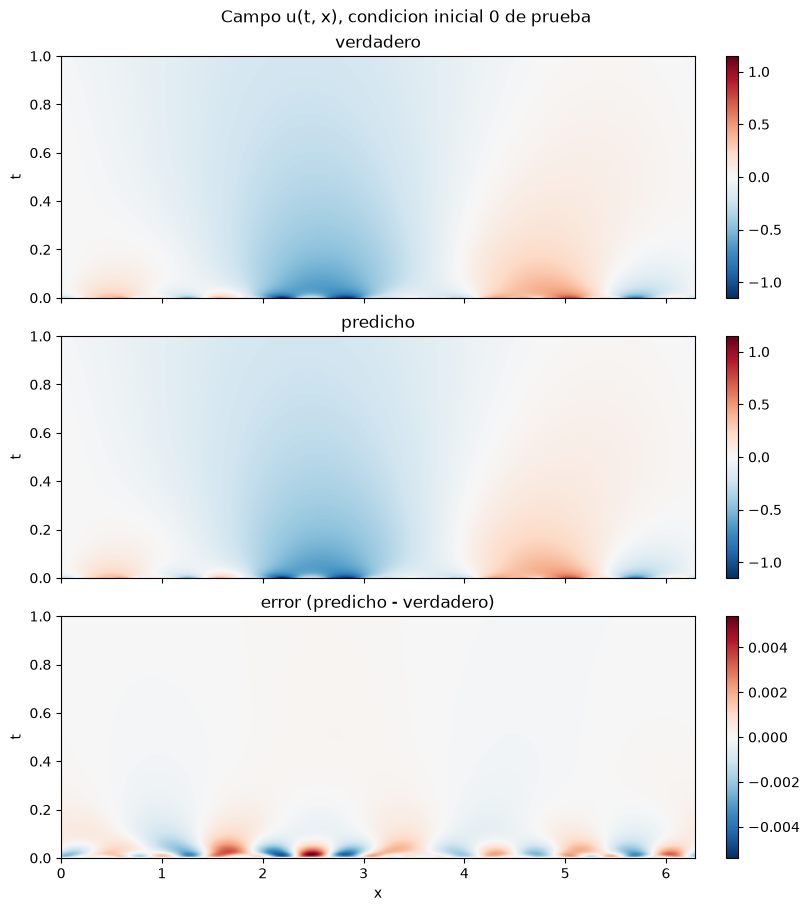

In [19]:
figures.field_figure(modelo, cargado.grf_test, cargado.results)

**Multiplicador.** $e^{-t a_\theta(k)}$, $e^{-t a(k)}$ y su diferencia sobre $(k,t)$ en la ventana de entrenamiento. Cada mapa dice cuanto sobrevive el modo $k$ en el tiempo $t$: $1$ (amarillo) intacto, $0$ (morado) amortiguado. La diferencia solo puede ser grande en la franja donde el multiplicador no es ni $1$ ni $0$, que es donde los datos informan sobre $a(k)$; fuera de ella un error en $a_\theta$ casi no cambia la trayectoria.

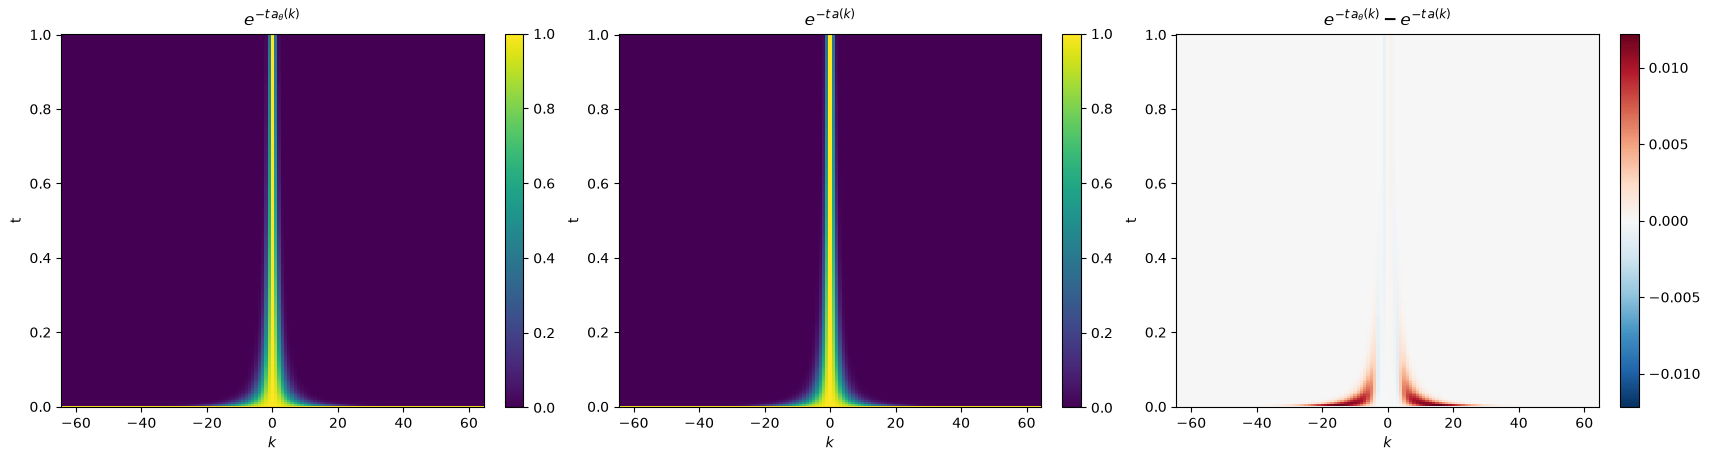

In [20]:
figures.multiplier_figure(modelo, cargado.reference, cargado.results, K=cargado.k_max)

**Simbolo fuera de la ventana.** $a_\theta(k)$ frente a la referencia hasta $|k|=1000$, y $h_\theta(k)=a_\theta(k)/\langle k\rangle^m$ con la banda $(c,C)$. A la izquierda, en log-log, la referencia $|k|^\alpha$ es una recta de pendiente $\alpha$: $a_\theta$ debe seguirla en la zona sombreada (ventana de entrenamiento); fuera de ella nada la ajusta y solo queda la banda. A la derecha, $h_\theta$ esta siempre entre $c$ y $C$ por construccion: si se aplana en un valor distinto del de la referencia, $a_\theta$ crece con el orden correcto $m$ pero con otra constante.

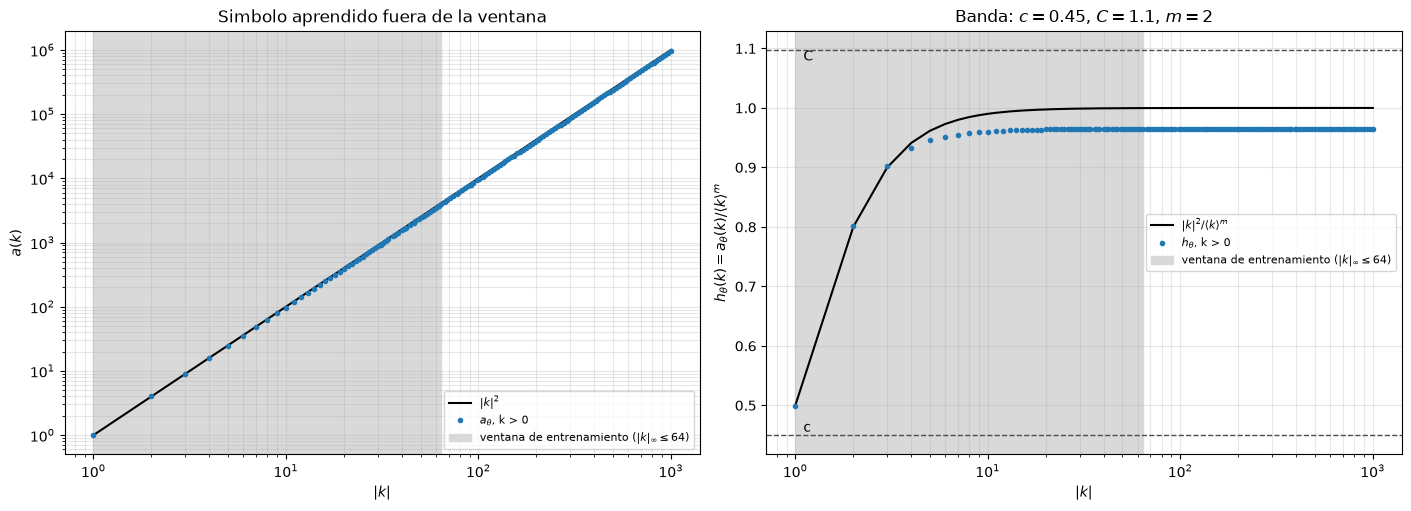

In [21]:
figures.symbol_extrapolation_figure(modelo, cargado.reference, cargado.results, k_window=cargado.k_max)

**Error contra $t$, con extrapolacion.** Error relativo $L^2$ en espacio fisico de las condiciones iniciales de prueba, hasta $t=3$. La curva es la media sobre las condiciones iniciales de prueba y la banda gris su minimo y maximo. Los marcadores separan los tiempos de entrenamiento, los intermedios ($t\le1$, no vistos) y la extrapolacion ($t>1$, zona sombreada): si el error no salta entre categorias, el modelo generaliza en $t$.

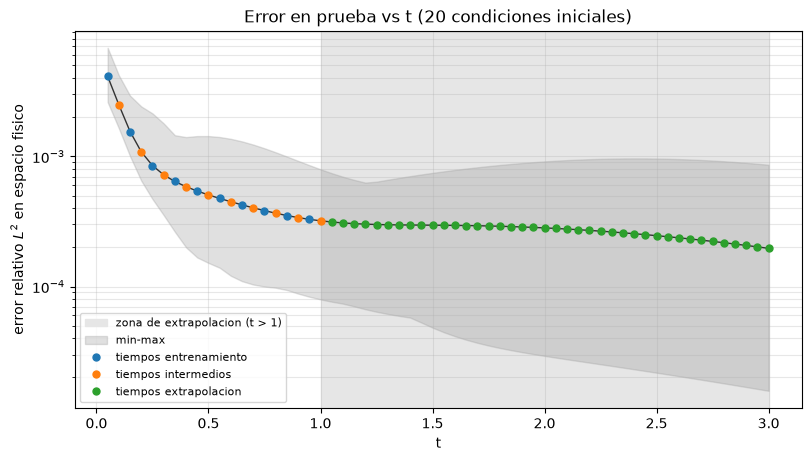

In [22]:
figures.extrapolation_error_figure(modelo, cargado.grf_test, cargado.results)

**Error del simbolo.** $|a_\theta(k)-a(k)|/|a(k)|$ en cada $k$ de entrenamiento y de validacion. Cada punto es un $k$ unico ($k=0$ se omite: ahi $a=0$). Los de validacion nunca se vieron al entrenar: si quedan a la altura de los de entrenamiento vecinos, la red interpola bien entre frecuencias.

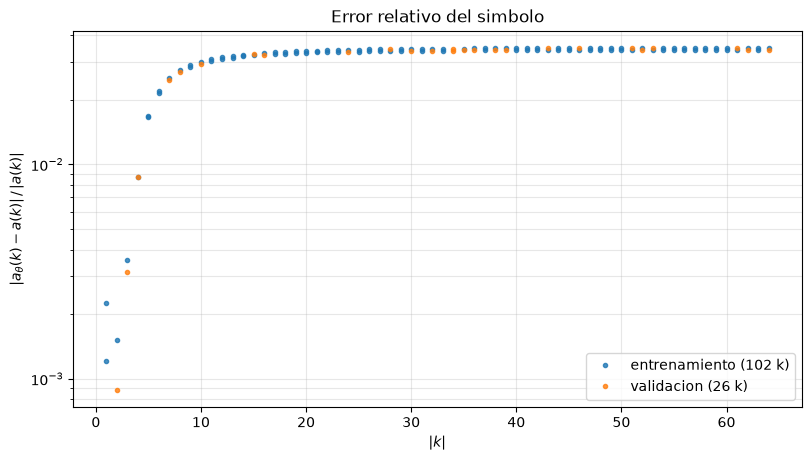

In [23]:
figures.symbol_error_figure(modelo, cargado.reference, cargado.train_data, cargado.val_data, cargado.results)

**Espectro de potencia.** $\mathbb{E}|\hat u(t,k)|^2$ medio de las condiciones iniciales de prueba, por capa de $|k|$, en $t\in\{0.05,0.25,1\}$. Una curva por tiempo, de oscuro a claro con $t$ creciente; continua es la verdadera y punteada la predicha (todos los modos de la malla, tambien los de fuera de la ventana). Si se superponen, el modelo amortigua bien cada escala.

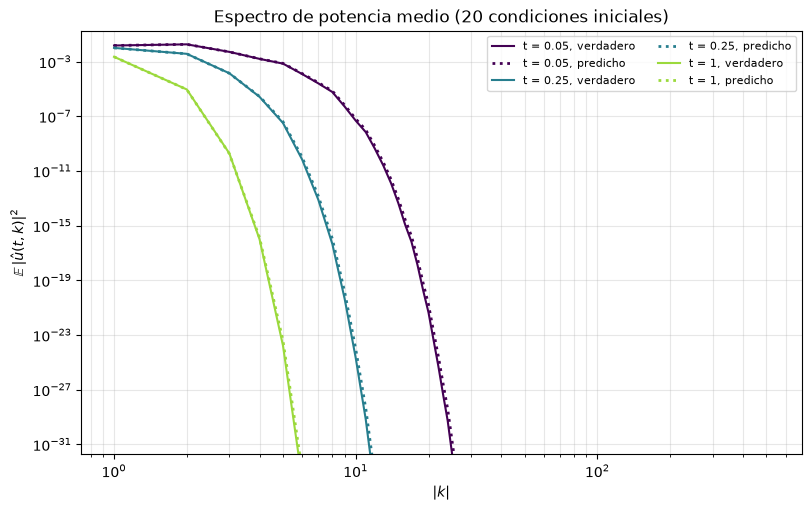

In [24]:
figures.power_spectrum_figure(modelo, cargado.grf_test, cargado.results)